In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.path as mplPath
import seaborn as sns
import FlowCal
import os
import pickle
import glob
from pathlib import Path
import re
# Inline backend for fast, static plots
%matplotlib inline

# Seaborn styling for publication-ready plots
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

## Configuration
Set paths to gates/mapping pickle and data directory.

In [2]:
# Path to saved gates + channel mapping
pickle_file = r"C:\Users\music\OneDrive\Desktop\CompLab\SynAD\data\Universal\flowgates_A7_incfluorescence_ICAM1.pkl"

# Directory containing FCS files (01-Well-*.fcs, 02-Well-*.fcs)
data_dir = r"I:\Shared drives\StallerLabSPA\Projects\Marissa\SyntheticADs\Izaiah_Flow_Data\20260521_ICAM1_SynADs_2d"

# Optional: plate layout CSV (8 rows × 12 cols with sample labels)
# Leave as None to use default well names (A1, A2, ..., H12)
layout_csv = r"C:\Users\music\OneDrive\Desktop\CompLab\SynAD\data\Universal\IZ_plate_layout_fullsequence.csv" 

# AD_ID <-> AAseq lookup for the synthetic ADs
ad_map_csv = r"C:\Users\music\Downloads\14synthsmap.csv"

In [3]:
# Load AD map (AD_ID -> AAseq) and build lookups in both directions
ad_map = pd.read_csv(ad_map_csv)

if ad_map['AD_ID'].duplicated().any() or ad_map['AAseq'].duplicated().any():
    raise ValueError(f"AD map contains duplicate AD_IDs or AAseqs: {ad_map_csv}")

id_to_seq = dict(zip(ad_map['AD_ID'], ad_map['AAseq']))
seq_to_id = dict(zip(ad_map['AAseq'], ad_map['AD_ID']))

print(f"Loaded {len(ad_map)} ADs from {os.path.basename(ad_map_csv)}")

Loaded 14 ADs from 14synthsmap.csv


## Load Gates & Channel Mapping
Load gate vertices and channel name mapping from pickle.

In [4]:
# Load gates and channel mapping from pickle
if not os.path.exists(pickle_file):
    raise FileNotFoundError(f"Gate file not found: {pickle_file}")

with open(pickle_file, "rb") as f:
    gate_data = pickle.load(f)

# Extract gate vertices using strict lookups
live_vertices = gate_data['live']
singles_vertices = gate_data['singles']
gfp_vertices = gate_data['gfp']
rfp_vertices = gate_data['rfp']
bfp_vertices = gate_data['bfp']

# Extract channel mapping (original → user description)
channel_mapping = gate_data['channel_mapping']

# Create reverse mapping (user description → original)
channel_mapping_rev = {v: k for k, v in channel_mapping.items()}

print(f"Loaded gates: live ({len(live_vertices)} vertices), singles ({len(singles_vertices)} vertices)")
print(f"Loaded fluorescence gates: GFP, RFP, BFP")
print(f"Channel mapping: {len(channel_mapping)} fluorescence channels")

print("\nMapped channels:")
for orig, mapped in sorted(channel_mapping.items()):
    print(f"  {orig:10s} -> {mapped}")

Loaded gates: live (13 vertices), singles (11 vertices)
Loaded fluorescence gates: GFP, RFP, BFP
Channel mapping: 3 fluorescence channels

Mapped channels:
  BB515-A    -> GFP
  BV421-A    -> BFP
  PE-CF594-A -> RFP


## Build Sample Dictionary from Plate Layout
Auto-discover FCS files and match to layout CSV (or default well names).

In [5]:
def build_samples_from_plate(data_dir, layout_csv=None):
    """
    Auto-discover FCS files and build samples dict from plate layout.
    
    Scans for files containing well IDs separated by underscores (e.g., Specimen_001_A1_A01.fcs).
    Maps to sample names directly from the layout CSV (e.g., 'ADname_1').
    
    Args:
        data_dir: Directory containing FCS files
        layout_csv: Path to CSV with up to 8 rows x 12 cols of sample labels (optional)
    
    Returns:
        dict: {sample_name: fcs_path, ...}
    
    Raises:
        FileNotFoundError: If CSV wells have no matching FCS files
        ValueError: If discovered files have no CSV entry or if layout exceeds bounds
    """
    # 1. Load or generate plate layout
    if layout_csv and os.path.exists(layout_csv):
        layout_df = pd.read_csv(layout_csv, header=None)
        
        # Strict validation: Ensure it does not exceed a standard 96-well plate size
        num_rows, num_cols = layout_df.shape
        if num_rows > 8 or num_cols > 12:
            raise ValueError(f"Layout CSV exceeds 96-well plate bounds (max 8x12), got {layout_df.shape}")
        
        print(f"Loaded plate layout from {os.path.basename(layout_csv)} with shape {layout_df.shape}")
    else:
        # Default: generate well IDs (A1-H12)
        rows = list('ABCDEFGH')
        cols = list(range(1, 13))
        layout_df = pd.DataFrame([[f"{r}{c}" for c in cols] for r in rows])
        num_rows, num_cols = 8, 12
        print("Using default well IDs (A1-H12)")
    
    # 2. Build well -> label mapping
    well_to_label = {}
    row_letters = list('ABCDEFGH')
    
    for i in range(num_rows):
        for j in range(num_cols):
            well_id = f"{row_letters[i]}{j+1}"
            label = layout_df.iloc[i, j]
            if pd.notna(label) and str(label).strip():  # Skip empty cells
                well_to_label[well_id] = str(label).strip()
    
    print(f"  Found {len(well_to_label)} wells with labels in layout")
    
    # 3. Discover FCS files dynamically
    fcs_files = glob.glob(os.path.join(data_dir, "*.fcs"))
    
    discovered_wells = set()
    file_map = {}  # well -> path
    
    # Regex to match exact, unpadded well IDs (e.g., A1, B12) and avoid padded ones like A01
    well_pattern = re.compile(r'^[A-H]([1-9]|1[0-2])$')
    
    for path in fcs_files:
        fname = os.path.basename(path)
        # Remove extension and split by underscore
        parts = fname.replace('.fcs', '').split('_')
        
        # Check each part of the filename for a valid well ID
        well = None
        for part in parts:
            if well_pattern.fullmatch(part):
                well = part
                break
        
        if well:
            discovered_wells.add(well)
            file_map[well] = path
            
    print(f"  Discovered {len(file_map)} valid FCS files containing well IDs")
    
    # 4. Validate: all CSV wells must have files
    csv_wells = set(well_to_label.keys())
    missing_files = csv_wells - discovered_wells
    if missing_files:
        raise FileNotFoundError(
            f"ERROR: Layout CSV lists wells with no matching FCS files: {sorted(missing_files)}\n"
            f"Ensure your FCS files contain these well IDs separated by underscores."
        )
        
    # 5. Validate: check for extra files not in CSV
    extra_files = discovered_wells - csv_wells
    if extra_files:
        raise ValueError(
            f"ERROR: Found FCS files for wells not listed in your layout CSV: {sorted(extra_files)}\n"
            f"Add these wells to your layout CSV or move the extra files out of the data directory."
        )
        
    # 6. Build final samples dict mapping direct label to file path
    samples = {}
    for well in sorted(csv_wells):
        label = well_to_label[well]
        samples[label] = file_map[well]
            
    print(f"Built samples dict: {len(samples)} samples mapped successfully")
        
    return samples

# Build samples dictionary
samples = build_samples_from_plate(data_dir, layout_csv)

Loaded plate layout from IZ_plate_layout_fullsequence.csv with shape (8, 7)
  Found 54 wells with labels in layout
  Discovered 54 valid FCS files containing well IDs
Built samples dict: 54 samples mapped successfully


## Load FCS Data & Apply Gates

In [6]:
def apply_gate(flow_data, vertices, channels):
    """Apply polygon gate to FlowCal data."""
    if not vertices or len(vertices) == 0:
        raise ValueError(f"Invalid or empty vertices provided for gate on channels {channels}.")
        
    points = np.column_stack((flow_data[:, channels[0]], flow_data[:, channels[1]]))
    path = mplPath.Path(vertices)
    mask = path.contains_points(points)
    return flow_data[mask]

# Load all FCS files
print("Loading FCS files...")
raw_data = {}
for name, path in samples.items():
    raw_data[name] = FlowCal.io.FCSData(path)

print(f"Loaded {len(raw_data)} FCS files")

# Apply gates
print("\nApplying gates...")
live_channels = ['FSC-A', 'SSC-A']
singles_channels = ['FSC-A', 'FSC-H']

gated_singles = {}
for name, data in raw_data.items():
    live = apply_gate(data, live_vertices, live_channels)
    singles = apply_gate(live, singles_vertices, singles_channels)
    gated_singles[name] = singles
    print(f"  {name:20s}: {data.shape[0]:6d} -> {live.shape[0]:6d} -> {singles.shape[0]:6d} events")

print(f"\nGated {len(gated_singles)} samples")

Loading FCS files...


Loaded 54 FCS files

Applying gates...
  20xGS_1             :  10000 ->   5749 ->   5620 events
  20xGS_2             :  10000 ->   6351 ->   6199 events
  20xGS_3             :  10000 ->   6845 ->   6696 events
  AFTDSPNQLNNILGDEDDPLVPFDQFINLVSDNSNKNAFF_1:  10000 ->   6212 ->   6035 events
  AFTDSPNQLNNILGDEDDPLVPFDQFINLVSDNSNKNAFF_2:  10000 ->   6568 ->   6389 events
  AFTDSPNQLNNILGDEDDPLVPFDQFINLVSDNSNKNAFF_3:  10000 ->   6625 ->   6470 events
  untransfected_1     :  10000 ->   6435 ->   6216 events
  VP16c_1             :  10000 ->   5254 ->   4948 events
  VP16c_2             :  10000 ->   5867 ->   5600 events
  VP16c_3             :  10000 ->   6324 ->   6087 events
  ELTFDEFIEQFTEEDITKLLDTPRSKPSSYFFNYDTSQDY_1:  10000 ->   5616 ->   5465 events
  ELTFDEFIEQFTEEDITKLLDTPRSKPSSYFFNYDTSQDY_2:  10000 ->   5956 ->   5833 events
  ELTFDEFIEQFTEEDITKLLDTPRSKPSSYFFNYDTSQDY_3:  10000 ->   6348 ->   6221 events
  untransfected_2     :  10000 ->   6952 ->   6772 events
  VPR_1          

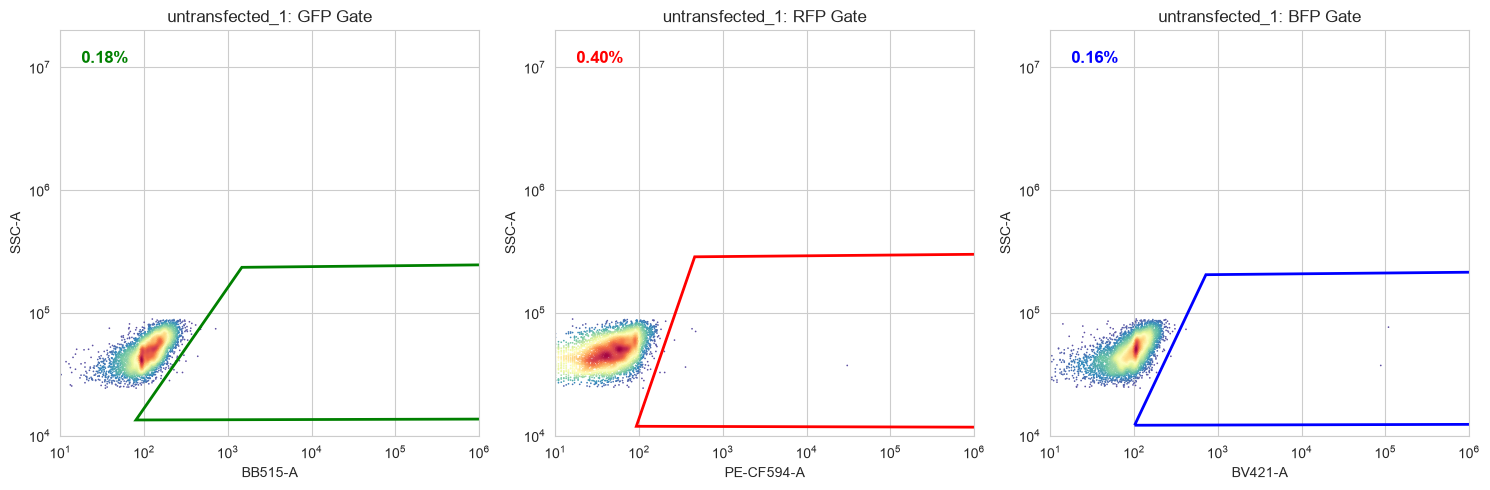

In [7]:
import matplotlib.patches as patches

def plot_fluorescence_gates(sample_name):
    """
    Plots GFP, RFP, and BFP gates over the live+singles gated data for a specified sample.
    """
    # Strict validation: prevent silent failures if the sample name is misspelled
    if sample_name not in gated_singles:
        raise KeyError(f"Sample '{sample_name}' not found in gated_singles. Available samples: {list(gated_singles.keys())}")
        
    sample_data = gated_singles[sample_name]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # Setup a list of tuples containing (Name, X-Channel, Vertices, Axes Object, Color)
    visualization_setup = [
        ('GFP', channel_mapping_rev['GFP'], gfp_vertices, axes[0], 'green'),
        ('RFP', channel_mapping_rev['RFP'], rfp_vertices, axes[1], 'red'),
        ('BFP', channel_mapping_rev['BFP'], bfp_vertices, axes[2], 'blue')
    ]

    for gate_name, fl_channel, vertices, ax, color in visualization_setup:
        # Set the current active axis for FlowCal to use, avoiding the 'ax' argument conflict
        plt.sca(ax)
        
        # 1. Plot the single-cell data
        FlowCal.plot.density2d(
            sample_data, 
            channels=[fl_channel, 'SSC-A'], 
            mode='scatter', 
            sigma=5
        )
        
        # 2. Format the axes limits to match the drawing environment
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlim(1e1, 1e6)
        ax.set_ylim(1e4, 2e7)
        ax.set_title(f"{sample_name}: {gate_name} Gate")
        
        # 3. Overlay the polygon
        poly = patches.Polygon(
            vertices, 
            closed=True, 
            fill=False, 
            edgecolor=color, 
            linewidth=2
        )
        ax.add_patch(poly)
        
        # 4. Calculate and display the percentage of cells in the gate
        points = np.column_stack((sample_data[:, fl_channel], sample_data[:, 'SSC-A']))
        path = mplPath.Path(vertices)
        mask = path.contains_points(points)
        pct = (np.sum(mask) / sample_data.shape[0]) * 100
        ax.text(0.05, 0.95, f"{pct:.2f}%", transform=ax.transAxes, 
                va='top', fontsize=12, color=color, fontweight='bold')

    plt.tight_layout()
    plt.show()

# --- Example Usage ---
# Replace 'Your_Sample_Name_Here.fcs' with a valid key from your dictionary
sample_to_view = 'untransfected_1'
plot_fluorescence_gates(sample_to_view)

## DataFrame Conversion & Gate Preview Helpers

In [8]:
# Cache for DataFrames (lazy conversion)
_df_cache = {}

def preview_gates(sample_name, use_raw=True):
    """
    Preview live and singles gates overlaid on a sample.
    
    Args:
        sample_name: Sample key to visualize
        use_raw: Use raw data (True) or gated data (False)
    """
    data_dict = raw_data if use_raw else gated_singles
    if sample_name not in data_dict:
        raise KeyError(f"Sample '{sample_name}' not found")
    
    data = data_dict[sample_name]
    
    # Live gate
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    
    # Plot live gate on first subplot
    plt.sca(axes[0])  # Set current axis
    FlowCal.plot.density2d(data, channels=['FSC-A', 'SSC-A'], mode='scatter', sigma=5)
    axes[0].set_xscale('log')
    axes[0].set_yscale('log')
    axes[0].set_xlim(1e4, 2e7)
    axes[0].set_ylim(1e4, 2e7)
    axes[0].set_title(f"Live Gate - {sample_name}")
    if live_vertices:
        poly = plt.Polygon(live_vertices, closed=True, edgecolor='red', facecolor='none', linewidth=2)
        axes[0].add_patch(poly)
    
    # Plot singles gate on second subplot (on live-gated data)
    plt.sca(axes[1])  # Set current axis
    live_gated = apply_gate(data, live_vertices, ['FSC-A', 'SSC-A'])
    FlowCal.plot.density2d(live_gated, channels=['FSC-A', 'FSC-H'], mode='scatter', sigma=5)
    axes[1].set_xscale('log')
    axes[1].set_yscale('log')
    axes[1].set_xlim(2e4, 2e5)
    axes[1].set_ylim(1e4, 1e5)
    axes[1].set_title(f"Singles Gate - {sample_name}")
    if singles_vertices:
        poly = plt.Polygon(singles_vertices, closed=True, edgecolor='red', facecolor='none', linewidth=2)
        axes[1].add_patch(poly)
    
    sns.despine(fig=fig)
    plt.tight_layout()
    plt.show()

print("Helper ready: preview_gates(sample_name)")

Helper ready: preview_gates(sample_name)


## Plotting Helpers (Seaborn/Matplotlib)

In [9]:
def resolve_channel(channel_name):
    if channel_name in channel_mapping_rev:
        return channel_mapping_rev[channel_name]
    return channel_name

def plot_hist(channel, sample_keys, bins='log', normalize=True, log_scale=True, 
              palette=None, figsize=(8, 5), vlines=None):
    """
    Plot histogram overlay for multiple samples.
    
    Args:
        channel: Channel name (accepts mapped or original names)
        sample_keys: List of sample names to plot
        bins: 'log' for log-spaced bins, or int for number of bins
        normalize: Normalize to show fraction of total cells per bin (True)
        log_scale: Use log scale for x-axis
        palette: Seaborn palette dict
        figsize: Figure size
        vlines: Int, float, or list of values to draw vertical threshold lines
    """
    if isinstance(sample_keys, str):
        raise TypeError(f"sample_keys must be a list (e.g., ['{sample_keys}']), but received a string.")
        
    orig_channel = resolve_channel(channel)
    
    if bins == 'log':
        bins = np.logspace(0, 7, 150)
    
    if palette is None:
        colors = sns.color_palette('deep', n_colors=len(sample_keys))
    elif isinstance(palette, dict):
        colors = [palette.get(key, '#888888') for key in sample_keys]
    else:
        colors = sns.color_palette(palette, n_colors=len(sample_keys))
    
    fig, ax = plt.subplots(figsize=figsize)
    
    all_counts = []
    all_centers = []
    
    for key in sample_keys:
        data = gated_singles[key]
        counts, edges = np.histogram(data[:, orig_channel], bins=bins, density=False)
        counts = counts.astype(float)
        
        if normalize and counts.sum() > 0:
            counts = counts / counts.sum()
            
        centers = (edges[:-1] + edges[1:]) / 2
        all_counts.append(counts)
        all_centers.append(centers)
    
    max_count = max(c.max() for c in all_counts)
    offset_step = max_count * 0.6  
    
    for i, key in enumerate(sample_keys):
        counts = all_counts[i]
        centers = all_centers[i]
        
        offset = i * offset_step
        ax.fill_between(centers, offset, counts + offset, alpha=0.6, label=key, color=colors[i])
        ax.plot(centers, counts + offset, color='white', lw=1.2)
    
    # NEW: Draw vertical threshold lines
    if vlines is not None:
        if isinstance(vlines, (int, float)):
            vlines = [vlines]
        for v in vlines:
            ax.axvline(x=v, color='black', linestyle='--', linewidth=2, zorder=10, label=f'Gate: {v}')
            
    if log_scale:
        ax.set_xscale('log')
    ax.set_xlabel(channel)
    
    if normalize:
        ax.set_yticks([])
        ax.set_title(f"{channel} - Normalized (Fraction of Total Cells)")
    else:
        ax.set_ylabel('Counts')
        ax.set_title(f"{channel} - Raw Event Counts")
    
    # Filter duplicate labels from legend
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys())
    
    sns.despine(ax=ax, left=normalize)
    plt.tight_layout()


print("Plotting helper ready: plot_hist(channel, samples)")

Plotting helper ready: plot_hist(channel, samples)


## Example: Preview Gates on a Sample

Previewing gates on: untransfected_3


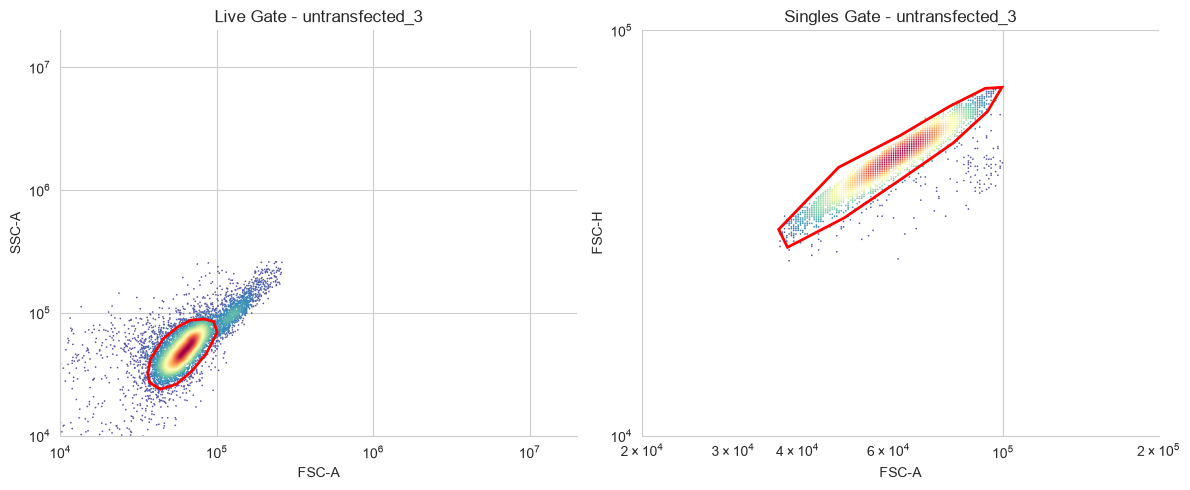

In [10]:
# Preview gates on first sample (change to any sample name)
sample_to_preview = list(samples.keys())[20]
print(f"Previewing gates on: {sample_to_preview}")
preview_gates(sample_to_preview)

## Histogram Overlays for BFP/RFP Thresh

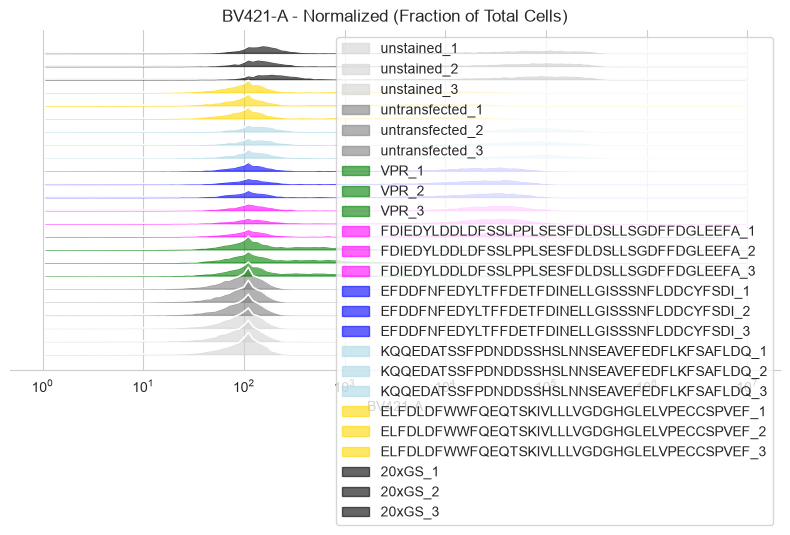

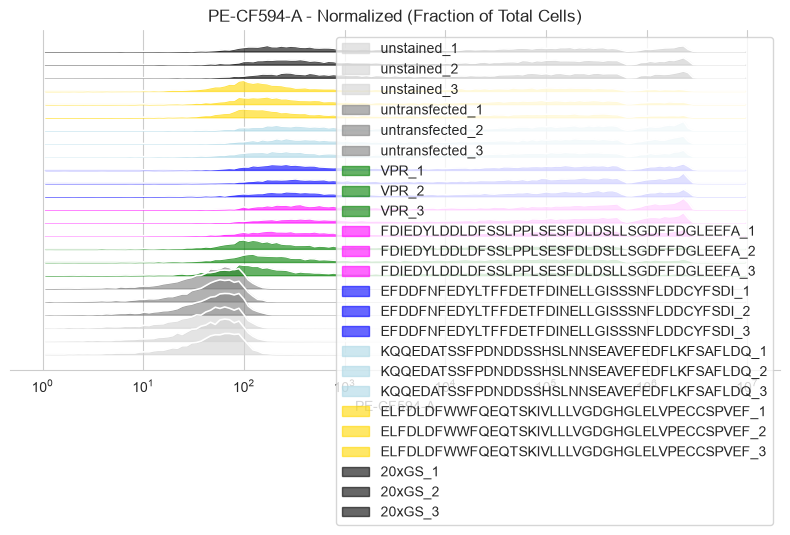

In [11]:
# Define your list of samples
my_samples = ['unstained_1', 'unstained_2', 'unstained_3', 'untransfected_1', 'untransfected_2', 'untransfected_3', 'VPR_1', 'VPR_2', 'VPR_3', '4_1', '4_2', '4_3', '6_1', '6_2', '6_3', '3_1','3_2','3_3', '14_1','14_2','14_3', '20xGS_1', '20xGS_2', '20xGS_3']

# Conditions to overlay, with one color per condition (ADs referenced by AD_ID)
condition_colors = {
    'unstained': 'lightgray',
    'untransfected': 'gray',
    'VPR': 'green',
    id_to_seq[4]: 'magenta',
    id_to_seq[6]: 'blue',
    id_to_seq[1]: 'lightblue',
    id_to_seq[14]: 'gold',
    '20xGS': 'black'
}

# Expand to all three replicates of each condition
my_samples = [f"{cond}_{rep}" for cond in condition_colors for rep in (1, 2, 3)]
color_map = {s: condition_colors[s.rsplit('_', 1)[0]] for s in my_samples}

# {'BB515-A': 'GFP', 'BV421-A': 'BFP', 'PE-CF594-A': 'RFP'}
# Pass the dictionary to the palette argument
plot_hist('BV421-A', my_samples, palette=color_map,
normalize=True
)
plot_hist('PE-CF594-A', my_samples, palette=color_map,
normalize=True
)

## Summary Stats for all wells

In [12]:
# GFP_MFI: median GFP of RFP+/BFP+ cells
# Perc_GFP+: % GFP+ cells within the RFP+/BFP+ population

# --- 1. Apply Gates and Calculate Summary Statistics ---
summary_stats = []

# Samples to exclude from fluor-gated metrics
exclude_samples = ['unstained_1', 'unstained_2', 'unstained_3']

# Map channels back to original names for gating
rfp_orig = channel_mapping_rev['RFP']
bfp_orig = channel_mapping_rev['BFP']
gfp_orig = channel_mapping_rev['GFP']

rfp_ch_idx = [rfp_orig, 'SSC-A']
bfp_ch_idx = [bfp_orig, 'SSC-A']

print("Extracting summary statistics...")

for sample, data in gated_singles.items(): 
    # Strict validation for input data shape
    if data.shape[0] == 0:
        raise ValueError(f"Sample '{sample}' has 0 cells in the Live/Singles gate. Halting execution.")
        
    # Strictly parse Condition and Replicate to ensure naming conventions are met
    if '_' not in sample:
        raise ValueError(f"Sample name '{sample}' does not contain an underscore. Expected format 'Condition_Replicate'.")
    condition, replicate_str = sample.rsplit('_', 1)
    replicate = int(replicate_str)

    # Initialize metrics as NaN
    fluor_gated_mfi = np.nan
    fluor_gated_perc = np.nan

    # Calculate targeted metrics ONLY for experimental samples
    if sample not in exclude_samples:
        # A. Apply RFP/BFP gates
        if condition == 'untransfected':
            # A. Untransfected cells have no RFP/BFP, so use all live/single cells
            gated_pop = data
        else:
            # A. Apply RFP/BFP gates
            rfp_pos = apply_gate(data, rfp_vertices, rfp_ch_idx)
            gated_pop = apply_gate(rfp_pos, bfp_vertices, bfp_ch_idx)
            
            if gated_pop.shape[0] == 0:
                raise ValueError(f"Experimental sample '{sample}' has 0 cells in the RFP+/BFP+ gate. Halting execution.")
            
        # B. fluor_gated_mfi: Median GFP of RFP+/BFP+ cells
        fluor_gated_mfi = np.median(gated_pop[:, gfp_orig])
        
        # C. Apply GFP gate to the RFP+/BFP+ population
        points = np.column_stack((gated_pop[:, gfp_orig], gated_pop[:, 'SSC-A']))
        gfp_path = mplPath.Path(gfp_vertices)
        is_gfp_positive = gfp_path.contains_points(points)
        
        # D. fluor_gated_perc: Percent of GFP+ cells out of RFP+/BFP+ cells
        fluor_gated_perc = (np.sum(is_gfp_positive) / gated_pop.shape[0]) * 100

    # Store calculated metrics for this sample
    summary_stats.append({
        'Sample': sample,
        'Condition': condition,
        'Replicate': replicate,
        'GFP_MFI': fluor_gated_mfi,
        'Perc_GFP+': fluor_gated_perc
    })

# Compile final Summary DataFrame
summary_df = pd.DataFrame(summary_stats)

# Keep only experimental data by dropping excluded samples
summary_df = summary_df[~summary_df['Sample'].isin(exclude_samples)].copy()

expected_replicates = summary_df['Replicate'].unique()

summary_df.reset_index(drop=True, inplace=True)

print(f"Summary DataFrame created successfully with {len(summary_df)} experimental wells.")

Extracting summary statistics...
Summary DataFrame created successfully with 51 experimental wells.


In [13]:
# Replace AAseq conditions with their AD_ID; rename controls
control_names = {
    '20xGS': '20xGS',
    'VPR': 'VPR',
    'VP16c': 'VP16-Cterm',
    'untransfected': 'Untransfected'
}
summary_df['Condition'] = summary_df['Condition'].map({**seq_to_id, **control_names})

summary_df.drop(columns=['Sample'],inplace=True)
summary_df.head()

,Condition,Replicate,GFP_MFI,Perc_GFP+
0,20xGS,1,164.042801,2.412545
1,20xGS,2,163.922775,2.087525
2,20xGS,3,161.321655,1.769685
3,7,1,157.398285,2.197802
4,7,2,150.988312,1.802885


### Saving

In [14]:
summary_df.to_csv(r'C:\Users\music\OneDrive\Desktop\CompLab\SynAD\Publication\GitHub\data\HEK293T14_ICAM1_AD_ID.csv', index=False)